# Marriage During University and Academic Performance
### Web scraping, data integration and preprocessing, then analysis

**Question:** does being married during university go with better or worse academic performance than being unmarried?

This notebook collects data from **two real public sources**, builds one unified table, cleans it, and compares married and unmarried students. Nothing is typed in by hand or simulated: every number comes from the two sources below, fetched when the notebook runs.

**Research questions**
1. Do married and unmarried students have different academic outcomes?
2. Which group shows better performance (grades, share of high or low performers, dropout, units passed)?
3. Are there differences in attendance pattern (daytime or evening)? Data on time management, motivation and study habits split by marital status is checked for, and its absence is reported honestly.
4. What can and cannot be said about benefits and challenges of marriage during university from this data?

**Important:** the data is observational. Any difference found is an association. It does **not** show that marriage causes better or worse results (age, work, finances, field of study and many other things differ between the groups).

## 1. Data sources and scraping methodology

I searched for sources with a marital-status field **and** an academic-performance field, then inspected each page before using it.

| | Source A | Source B |
|---|---|---|
| Site | UCI Machine Learning Repository, dataset 697 | PubMed Central (PMC), article PMC11585708 |
| What it is | Student-level administrative records, 4,424 undergraduates of a Portuguese polytechnic institute (Realinho et al., 2021). Marital status plus first- and second-semester grades. | Published cross-sectional study of 633 female undergraduates at Aksum University, Ethiopia (Wube et al., *Global Epidemiology*, 2024, doi:10.1016/j.gloepi.2024.100175). Table 1 gives marital status by performance level. |
| Type of data | **Student-level observations** (anonymised, no names or IDs) | **Aggregate published counts** (cell counts of a published table) |
| Performance measure | Grades on the Portuguese 0-20 scale | CGPA on a 0-4 scale, grouped as Poor, Satisfactory, Good, Excellent |
| Method | `requests` for the UCI JSON API (metadata) and the dataset ZIP | `requests` to NCBI E-utilities (`efetch`, official API for this open-access article) + `BeautifulSoup` to parse the table |
| Licence / policy | UCI dataset is published for public reuse (CC BY 4.0 per the UCI page). | Open-access article (CC BY-NC-ND). Fetched once through NCBI's official API with a descriptive User-Agent. The website's bot challenge is respected, not bypassed. |

**Why the two sources are only partly compatible, and how I handle it.** Both give *marital status* and *academic performance for university students*, but one is student-level and the other aggregated, and they use different grade scales and different populations (Portugal vs Ethiopia, mixed-gender vs women only). I therefore:
- keep a `Record_Type` column (`student-level` vs `aggregate-count`) and a `Source` column on every row;
- never turn aggregate counts into invented individual students (each aggregate row carries a count `N`);
- compare the two sources **side by side on a harmonised 4-level performance scale** (defined in section 5), and never pool them into a single statistic;
- run the richer analysis (grades, age adjustment, dropout) on Source A only, because only it has the needed fields.

Ethics: no personally identifiable information is collected. Source A is already anonymised; Source B is aggregate.

In [1]:
import io, re, time, zipfile, json, warnings, os
import requests
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40, "display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("figures", exist_ok=True)
os.makedirs("raw", exist_ok=True)

HEADERS = {"User-Agent": "Mozilla/5.0 (university coursework notebook; contact: student; polite, 1 request/page)"}

## 2. Scraping Source A: UCI Machine Learning Repository (student-level data)
I first read the dataset's JSON metadata (to confirm what the variables mean), then download the dataset ZIP.

In [2]:
UCI_ID = 697
UCI_API = f"https://archive.ics.uci.edu/api/dataset?id={UCI_ID}"
UCI_ZIP = "https://archive.ics.uci.edu/static/public/697/predict+students+dropout+and+academic+success.zip"
UCI_PAGE = "https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success"

meta = requests.get(UCI_API, headers=HEADERS, timeout=60).json()["data"]
print("Name        :", meta["name"])
print("Instances   :", meta["num_instances"], "| Features:", meta["num_features"])
print("Creators    :", ", ".join(meta["creators"]))
print("Paper       :", meta["intro_paper"]["title"], f"({meta['intro_paper']['year']})")
print("Missing vals:", meta["has_missing_values"])

# Inspect how marital status is coded before using it.
marital_codes_text = [v for v in meta["variables"] if v["name"].lower() == "marital status"][0]["description"]
print("\nMarital status coding according to UCI:", marital_codes_text)

# Policy: the dataset is offered for download on the UCI page. We use that official file.
resp = requests.get(UCI_ZIP, headers=HEADERS, timeout=120)
resp.raise_for_status()
with zipfile.ZipFile(io.BytesIO(resp.content)) as z:
    print("\nFiles in ZIP:", z.namelist())
    raw_a = pd.read_csv(z.open("data.csv"), sep=";", encoding="utf-8-sig")
raw_a.to_csv("raw/uci_697_raw.csv", index=False)
raw_a.columns = [c.strip() for c in raw_a.columns]
print("Raw shape:", raw_a.shape)

Name        : Predict Students' Dropout and Academic Success
Instances   : 4424 | Features: 36
Creators    : Valentim Realinho, Mónica Vieira Martins, Jorge Machado, Luís Baptista
Paper       : Early prediction of student's performance in higher education: a case study (2021)
Missing vals: no

Marital status coding according to UCI: 1 – single 2 – married 3 – widower 4 – divorced 5 – facto union 6 – legally separated



Files in ZIP: ['data.csv']
Raw shape: (4424, 37)


**Inspection result.** The file has one row per student, a coded `Marital status`, `Age at enrollment`, `Gender`, daytime/evening attendance, scholarship status, curricular units enrolled/approved and the **average grade of each semester (0-20)**, plus a `Target` (Dropout / Enrolled / Graduate). Marital status is the *status at enrolment*, so it is not tracked over time.

In [3]:
# Build the Source A frame: keep only the columns relevant to the research question.
cols_a = {
    "Marital status": "Marital_Status_Raw",
    "Gender": "Gender_Raw",
    "Age at enrollment": "Age",
    "Daytime/evening attendance": "Attendance_Mode_Raw",
    "Scholarship holder": "Scholarship_Raw",
    "Curricular units 1st sem (enrolled)": "Sem1_Units_Enrolled",
    "Curricular units 1st sem (approved)": "Sem1_Units_Approved",
    "Curricular units 1st sem (grade)": "Sem1_Grade",
    "Curricular units 2nd sem (enrolled)": "Sem2_Units_Enrolled",
    "Curricular units 2nd sem (approved)": "Sem2_Units_Approved",
    "Curricular units 2nd sem (grade)": "Sem2_Grade",
    "Target": "Outcome_Target",
}
# the attendance column name contains a stray tab in the original file; match it loosely
lookup = {re.sub(r"\s+", " ", c).strip(): c for c in raw_a.columns}
df_a = raw_a[[lookup[re.sub(r"\s+"," ",k).strip()] for k in cols_a]].copy()
df_a.columns = list(cols_a.values())
df_a.insert(0, "Source", "UCI ML Repository #697 (Realinho et al., 2021)")
df_a.insert(1, "Record_Type", "student-level")
df_a.insert(2, "Population", "Portuguese polytechnic institute, mixed gender")
df_a["Source_URL"] = UCI_PAGE
# The file has no student ID. Identical rows are only treated as duplicates if ALL 37 original columns match.
full_dups = raw_a.duplicated(keep="first")
print("Rows identical in all 37 original columns:", int(full_dups.sum()))
df_a["_dup_full"] = full_dups.values
for c in ["Marital_Status_Raw", "Gender_Raw", "Attendance_Mode_Raw", "Scholarship_Raw"]:
    df_a[c] = df_a[c].astype(str)   # numeric codes kept as the original labels (decoded in preprocessing)
# UCI coding: Gender 1=male 0=female; Daytime/evening 1=daytime 0=evening; Scholarship 1=yes 0=no
print(df_a.shape)
display(df_a.head())

Rows identical in all 37 original columns: 0
(4424, 17)


,Source,Record_Type,Population,Marital_Status_Raw,Gender_Raw,Age,Attendance_Mode_Raw,Scholarship_Raw,Sem1_Units_Enrolled,Sem1_Units_Approved,Sem1_Grade,Sem2_Units_Enrolled,Sem2_Units_Approved,Sem2_Grade,Outcome_Target,Source_URL,_dup_full
0,"UCI ML Repository #697 (Realinho et al., 2021)",student-level,"Portuguese polytechnic institute, mixed gender",1,1,20,1,0,0,0,0.000000,0,0,0.000000,Dropout,https://archive.ics.uci.edu/dataset/697/predic...,False
1,"UCI ML Repository #697 (Realinho et al., 2021)",student-level,"Portuguese polytechnic institute, mixed gender",1,1,19,1,0,6,6,14.000000,6,6,13.666667,Graduate,https://archive.ics.uci.edu/dataset/697/predic...,False
2,"UCI ML Repository #697 (Realinho et al., 2021)",student-level,"Portuguese polytechnic institute, mixed gender",1,1,19,1,0,6,0,0.000000,6,0,0.000000,Dropout,https://archive.ics.uci.edu/dataset/697/predic...,False
3,"UCI ML Repository #697 (Realinho et al., 2021)",student-level,"Portuguese polytechnic institute, mixed gender",1,0,20,1,0,6,6,13.428571,6,5,12.400000,Graduate,https://archive.ics.uci.edu/dataset/697/predic...,False
4,"UCI ML Repository #697 (Realinho et al., 2021)",student-level,"Portuguese polytechnic institute, mixed gender",2,0,45,0,0,6,5,12.333333,6,6,13.000000,Graduate,https://archive.ics.uci.edu/dataset/697/predic...,False


## 3. Scraping Source B: PubMed Central article (aggregate published table)
Steps: (1) fetch the article once through NCBI's official E-utilities API (the public website serves a bot challenge to scripts, which is not bypassed), (2) read the XML, (3) read the study's own definition of performance levels, (4) parse the XML tables with BeautifulSoup, (5) validate the parsed numbers against the row totals printed in the paper.

In [4]:
PMC_ID = "11585708"
PMC_URL = f"https://pmc.ncbi.nlm.nih.gov/articles/PMC{PMC_ID}/"          # human-readable article page (used as the citation link)
# NCBI's own programmatic route (E-utilities). The website itself shows a bot challenge to scripts,
# and that challenge must not be bypassed, so the official API for the same open-access article is used instead.
EFETCH = f"https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi?db=pmc&id={PMC_ID}&retmode=xml"

time.sleep(1)   # polite delay; one request only
resp_b = requests.get(EFETCH, headers=HEADERS, timeout=60)
resp_b.raise_for_status()
open("raw/pmc_PMC11585708.xml", "w", encoding="utf-8").write(resp_b.text)
soup = BeautifulSoup(resp_b.text, "xml")
page_text = soup.get_text(" ", strip=True)

print("Title:", soup.find("article-title").get_text(strip=True))
print("Journal:", soup.find("journal-title").get_text(strip=True), "| DOI:", soup.find("article-id", {"pub-id-type": "doi"}).get_text())
print("Licence:", soup.find("license").find("license-p").get_text(strip=True)[:90])

# How does the paper define performance levels? (needed to harmonise with Source A)
defn = re.search(r"Excellent academic performance was defined.*?poor academic performance as a CGPA of [0-9.]+ to [0-9.]+\.", page_text).group(0)
print("\nStudy definition:", defn)
print("Design:", re.search(r"An institutional-based cross-sectional study was conducted involving \d+ female university students", page_text).group(0))

Title: Academic performance and associated factors among female university students
Journal: Global Epidemiology | DOI: 10.1016/j.gloepi.2024.100175
Licence: This is an open access article under the CC BY-NC-ND license (http://creativecommons.org/l

Study definition: Excellent academic performance was defined as a CGPA of 3.50 to 4.00, good academic performance as a CGPA of 2.75 to 3.49, satisfactory academic performance as a CGPA of 2.00 to 2.74, and poor academic performance as a CGPA of 0.00 to 1.99.
Design: An institutional-based cross-sectional study was conducted involving 633 female university students


In [5]:
def parse_count_cell(text):
    # Extract the integer count from cells like '53 (13.7 %)' or '9 (10 %)'; '0' means zero.
    if not isinstance(text, str): return np.nan
    t = text.replace("\xa0", " ").strip()
    m = re.match(r"^(\d+)", t)
    return int(m.group(1)) if m else np.nan

table1 = soup.find("table")                      # Table 1: socio-demographics by performance level
header = [c.get_text(" ", strip=True) for c in table1.find("tr").find_all(["th", "td"])]
print("Table 1 header:", header)

rows, current_var = [], None
for tr in table1.find_all("tr")[1:]:
    cells = [c.get_text(" ", strip=True).replace("\xa0", " ") for c in tr.find_all(["td", "th"])]
    if len(cells) == 7:            # variable name + category + 5 numeric cells
        current_var, cat, nums = cells[0], cells[1], cells[2:]
    elif len(cells) == 6:          # category + 5 numeric cells (variable name spans rows)
        cat, nums = cells[0], cells[1:]
    else:
        continue
    rows.append([current_var, cat] + nums)

table1_df = pd.DataFrame(rows, columns=["Variable", "Category", "Poor", "Satisfactory", "Good", "Excellent", "Total"])
print("Rows parsed from Table 1:", len(table1_df))
display(table1_df[table1_df["Variable"] == "Marital Status"])

Table 1 header: ['Variable', 'Category', 'Poor (n%)', 'Satisfactory (n%)', 'Good (n%)', 'Excellent (n%)', 'Total (n%)']
Rows parsed from Table 1: 32


,Variable,Category,Poor,Satisfactory,Good,Excellent,Total
6,Marital Status,Single,53 (13.7 %),129 (32.2 %),117 (30.2 %),89 (22.9 %),388 (61.3 %)
7,Marital Status,Married,9 (10 %),40 (44.4 %),25 (27.8 %),16 (17.8 %),90 (14.2 %)
8,Marital Status,With Fiancée,13 (8.4 %),58 (37.4 %),50 (32.3 %),34 (21.9 %),155 (24.5 %)


In [6]:
# Keep only the marital-status block and convert to long format (one row per marital group x performance level).
ms = table1_df[table1_df["Variable"].str.strip().str.lower() == "marital status"].copy()
levels = ["Poor", "Satisfactory", "Good", "Excellent"]

long_rows = []
for _, r in ms.iterrows():
    counts = {lv: parse_count_cell(r[lv]) for lv in levels}
    total_paper = parse_count_cell(r["Total"])
    # validation against the paper's own printed total
    assert sum(counts.values()) == total_paper, f"Parsed counts do not match printed total for {r['Category']}"
    for lv in levels:
        long_rows.append({"Marital_Status_Raw": r["Category"], "Performance_Level_Raw": lv,
                          "Count_Raw": r[lv]})

df_b = pd.DataFrame(long_rows)
df_b.insert(0, "Source", "Wube, Asgedom & Jemal (2024), Glob Epidemiol 8:100175, PMC11585708, Table 1")
df_b.insert(1, "Record_Type", "aggregate-count")
df_b.insert(2, "Population", "Female undergraduates, Aksum University, Ethiopia (n=633)")
df_b["Gender_Raw"] = "Female"
df_b["Source_URL"] = PMC_URL
print("Validation passed: parsed counts equal the totals printed in the paper for every marital group.")
print(df_b.shape)
display(df_b.head(8))

Validation passed: parsed counts equal the totals printed in the paper for every marital group.
(12, 8)


,Source,Record_Type,Population,Marital_Status_Raw,Performance_Level_Raw,Count_Raw,Gender_Raw,Source_URL
0,"Wube, Asgedom & Jemal (2024), Glob Epidemiol 8...",aggregate-count,"Female undergraduates, Aksum University, Ethio...",Single,Poor,53 (13.7 %),Female,https://pmc.ncbi.nlm.nih.gov/articles/PMC11585...
1,"Wube, Asgedom & Jemal (2024), Glob Epidemiol 8...",aggregate-count,"Female undergraduates, Aksum University, Ethio...",Single,Satisfactory,129 (32.2 %),Female,https://pmc.ncbi.nlm.nih.gov/articles/PMC11585...
2,"Wube, Asgedom & Jemal (2024), Glob Epidemiol 8...",aggregate-count,"Female undergraduates, Aksum University, Ethio...",Single,Good,117 (30.2 %),Female,https://pmc.ncbi.nlm.nih.gov/articles/PMC11585...
3,"Wube, Asgedom & Jemal (2024), Glob Epidemiol 8...",aggregate-count,"Female undergraduates, Aksum University, Ethio...",Single,Excellent,89 (22.9 %),Female,https://pmc.ncbi.nlm.nih.gov/articles/PMC11585...
4,"Wube, Asgedom & Jemal (2024), Glob Epidemiol 8...",aggregate-count,"Female undergraduates, Aksum University, Ethio...",Married,Poor,9 (10 %),Female,https://pmc.ncbi.nlm.nih.gov/articles/PMC11585...
5,"Wube, Asgedom & Jemal (2024), Glob Epidemiol 8...",aggregate-count,"Female undergraduates, Aksum University, Ethio...",Married,Satisfactory,40 (44.4 %),Female,https://pmc.ncbi.nlm.nih.gov/articles/PMC11585...
6,"Wube, Asgedom & Jemal (2024), Glob Epidemiol 8...",aggregate-count,"Female undergraduates, Aksum University, Ethio...",Married,Good,25 (27.8 %),Female,https://pmc.ncbi.nlm.nih.gov/articles/PMC11585...
7,"Wube, Asgedom & Jemal (2024), Glob Epidemiol 8...",aggregate-count,"Female undergraduates, Aksum University, Ethio...",Married,Excellent,16 (17.8 %),Female,https://pmc.ncbi.nlm.nih.gov/articles/PMC11585...


## 4. Initial DataFrames and data integration
Both frames are mapped onto **one shared set of column names**, then combined with `pd.concat()` (the two sources hold different rows, so concatenation, not a merge, is the right operation). Columns that exist only in one source stay empty (`NaN`) for the other. That is real structural missingness, not an error, and is handled explicitly later.

In [7]:
print("Source A (student-level) :", df_a.shape)
print("Source B (aggregate)      :", df_b.shape)

# Standardise names. Source B gets the same columns; fields it does not have remain NaN.
common_cols = ["Source", "Record_Type", "Population", "Source_URL",
               "Marital_Status_Raw", "Gender_Raw", "Age", "Attendance_Mode_Raw", "Scholarship_Raw",
               "Sem1_Units_Enrolled", "Sem1_Units_Approved", "Sem1_Grade",
               "Sem2_Units_Enrolled", "Sem2_Units_Approved", "Sem2_Grade",
               "Outcome_Target", "Performance_Level_Raw", "Count_Raw", "_dup_full"]
df_a_std = df_a.reindex(columns=common_cols)
df_b_std = df_b.reindex(columns=common_cols)
df_b_std["_dup_full"] = False

unified_raw = pd.concat([df_a_std, df_b_std], ignore_index=True)
print("Unified raw DataFrame:", unified_raw.shape)
print(unified_raw["Source"].value_counts().to_string())

Source A (student-level) : (4424, 17)
Source B (aggregate)      : (12, 8)
Unified raw DataFrame: (4436, 19)
Source
UCI ML Repository #697 (Realinho et al., 2021)                                 4424
Wube, Asgedom & Jemal (2024), Glob Epidemiol 8:100175, PMC11585708, Table 1      12


## 5. Data preprocessing
### 5.1 BEFORE preprocessing
`head()`, `info()`, `describe()` and `isnull().sum()` of the unified raw table.

In [8]:
print("=== HEAD (first rows: Source A) ===")
display(unified_raw.head())
print("\n=== HEAD (last rows: Source B) ===")
display(unified_raw.tail())
print("\n=== INFO ===")
unified_raw.info()
print("\n=== DESCRIBE (numeric) ===")
display(unified_raw.describe())
print("\n=== DESCRIBE (text columns) ===")
display(unified_raw.describe(include="object").T)
print("\n=== ISNULL().SUM() ===")
display(unified_raw.isnull().sum().to_frame("missing"))
print("Rows identical in all 37 original UCI columns (true duplicates):", int(unified_raw["_dup_full"].sum()))
print("Rows identical only on the reduced column set kept here (NOT duplicates, other fields differ):", int(unified_raw.drop(columns="_dup_full").duplicated().sum()))
print("Distinct raw marital labels:", sorted(unified_raw["Marital_Status_Raw"].dropna().unique()))

=== HEAD (first rows: Source A) ===


,Source,Record_Type,Population,Source_URL,Marital_Status_Raw,Gender_Raw,Age,Attendance_Mode_Raw,Scholarship_Raw,Sem1_Units_Enrolled,Sem1_Units_Approved,Sem1_Grade,Sem2_Units_Enrolled,Sem2_Units_Approved,Sem2_Grade,Outcome_Target,Performance_Level_Raw,Count_Raw,_dup_full
0,"UCI ML Repository #697 (Realinho et al., 2021)",student-level,"Portuguese polytechnic institute, mixed gender",https://archive.ics.uci.edu/dataset/697/predic...,1,1,20.0,1,0,0.0,0.0,0.000000,0.0,0.0,0.000000,Dropout,NaN,NaN,False
1,"UCI ML Repository #697 (Realinho et al., 2021)",student-level,"Portuguese polytechnic institute, mixed gender",https://archive.ics.uci.edu/dataset/697/predic...,1,1,19.0,1,0,6.0,6.0,14.000000,6.0,6.0,13.666667,Graduate,NaN,NaN,False
2,"UCI ML Repository #697 (Realinho et al., 2021)",student-level,"Portuguese polytechnic institute, mixed gender",https://archive.ics.uci.edu/dataset/697/predic...,1,1,19.0,1,0,6.0,0.0,0.000000,6.0,0.0,0.000000,Dropout,NaN,NaN,False
3,"UCI ML Repository #697 (Realinho et al., 2021)",student-level,"Portuguese polytechnic institute, mixed gender",https://archive.ics.uci.edu/dataset/697/predic...,1,0,20.0,1,0,6.0,6.0,13.428571,6.0,5.0,12.400000,Graduate,NaN,NaN,False
4,"UCI ML Repository #697 (Realinho et al., 2021)",student-level,"Portuguese polytechnic institute, mixed gender",https://archive.ics.uci.edu/dataset/697/predic...,2,0,45.0,0,0,6.0,5.0,12.333333,6.0,6.0,13.000000,Graduate,NaN,NaN,False



=== HEAD (last rows: Source B) ===


,Source,Record_Type,Population,Source_URL,Marital_Status_Raw,Gender_Raw,Age,Attendance_Mode_Raw,Scholarship_Raw,Sem1_Units_Enrolled,Sem1_Units_Approved,Sem1_Grade,Sem2_Units_Enrolled,Sem2_Units_Approved,Sem2_Grade,Outcome_Target,Performance_Level_Raw,Count_Raw,_dup_full
4431,"Wube, Asgedom & Jemal (2024), Glob Epidemiol 8...",aggregate-count,"Female undergraduates, Aksum University, Ethio...",https://pmc.ncbi.nlm.nih.gov/articles/PMC11585...,Married,Female,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Excellent,16 (17.8 %),False
4432,"Wube, Asgedom & Jemal (2024), Glob Epidemiol 8...",aggregate-count,"Female undergraduates, Aksum University, Ethio...",https://pmc.ncbi.nlm.nih.gov/articles/PMC11585...,With Fiancée,Female,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Poor,13 (8.4 %),False
4433,"Wube, Asgedom & Jemal (2024), Glob Epidemiol 8...",aggregate-count,"Female undergraduates, Aksum University, Ethio...",https://pmc.ncbi.nlm.nih.gov/articles/PMC11585...,With Fiancée,Female,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Satisfactory,58 (37.4 %),False
4434,"Wube, Asgedom & Jemal (2024), Glob Epidemiol 8...",aggregate-count,"Female undergraduates, Aksum University, Ethio...",https://pmc.ncbi.nlm.nih.gov/articles/PMC11585...,With Fiancée,Female,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Good,50 (32.3 %),False
4435,"Wube, Asgedom & Jemal (2024), Glob Epidemiol 8...",aggregate-count,"Female undergraduates, Aksum University, Ethio...",https://pmc.ncbi.nlm.nih.gov/articles/PMC11585...,With Fiancée,Female,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Excellent,34 (21.9 %),False



=== INFO ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4436 entries, 0 to 4435
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Source                 4436 non-null   object 
 1   Record_Type            4436 non-null   object 
 2   Population             4436 non-null   object 
 3   Source_URL             4436 non-null   object 
 4   Marital_Status_Raw     4436 non-null   object 
 5   Gender_Raw             4436 non-null   object 
 6   Age                    4424 non-null   float64
 7   Attendance_Mode_Raw    4424 non-null   object 
 8   Scholarship_Raw        4424 non-null   object 
 9   Sem1_Units_Enrolled    4424 non-null   float64
 10  Sem1_Units_Approved    4424 non-null   float64
 11  Sem1_Grade             4424 non-null   float64
 12  Sem2_Units_Enrolled    4424 non-null   float64
 13  Sem2_Units_Approved    4424 non-null   float64
 14  Sem2_Grade             4424 non-null   flo

,Age,Sem1_Units_Enrolled,Sem1_Units_Approved,Sem1_Grade,Sem2_Units_Enrolled,Sem2_Units_Approved,Sem2_Grade
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,23.265145,6.270570,4.706600,10.640822,6.232143,4.435805,10.230206
std,7.587816,2.480178,3.094238,4.843663,2.195951,3.014764,5.210808
min,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,5.000000,3.000000,11.000000,5.000000,2.000000,10.750000
50%,20.000000,6.000000,5.000000,12.285714,6.000000,5.000000,12.200000
75%,25.000000,7.000000,6.000000,13.400000,7.000000,6.000000,13.333333
max,70.000000,26.000000,26.000000,18.875000,23.000000,20.000000,18.571429



=== DESCRIBE (text columns) ===


,count,unique,top,freq
Source,4436,2,"UCI ML Repository #697 (Realinho et al., 2021)",4424
Record_Type,4436,2,student-level,4424
Population,4436,2,"Portuguese polytechnic institute, mixed gender",4424
Source_URL,4436,2,https://archive.ics.uci.edu/dataset/697/predic...,4424
Marital_Status_Raw,4436,9,1,3919
Gender_Raw,4436,3,0,2868
Attendance_Mode_Raw,4424,2,1,3941
Scholarship_Raw,4424,2,0,3325
Outcome_Target,4424,3,Graduate,2209
Performance_Level_Raw,12,4,Poor,3



=== ISNULL().SUM() ===


,missing
Source,0
Record_Type,0
Population,0
Source_URL,0
Marital_Status_Raw,0
Gender_Raw,0
Age,12
Attendance_Mode_Raw,12
Scholarship_Raw,12
Sem1_Units_Enrolled,12


Rows identical in all 37 original UCI columns (true duplicates): 0
Rows identical only on the reduced column set kept here (NOT duplicates, other fields differ): 326
Distinct raw marital labels: ['1', '2', '3', '4', '5', '6', 'Married', 'Single', 'With Fiancée']


### 5.2 Cleaning steps
1. **Text cleaning:** trim, remove non-breaking spaces, unify case and accents.
2. **Standardise marital status** into one scheme for both sources:
   - `Married` (UCI code 2, Aksum "Married")
   - `Single` (UCI code 1, Aksum "Single")
   - `Engaged` (Aksum "With Fiancée", not a UCI category)
   - `Cohabiting` (UCI code 5 "facto union")
   - `Previously married` (UCI codes 3 widower, 4 divorced, 6 legally separated)
   - plus a binary `Married_Group`: **Married** vs **Unmarried** (Single + Engaged). Cohabiting and previously married are kept apart from "Unmarried" for the main comparison because they are different situations and have very small numbers.
3. **Data types:** counts to integers, categorical columns to `category`, `N` (students represented by the row) added: 1 for student-level rows, the published count for aggregate rows.
4. **Standardise academic performance** to the study's own four levels: Poor, Satisfactory, Good, Excellent. For Source B they are given directly (CGPA 0-1.99 / 2.00-2.74 / 2.75-3.49 / 3.50-4.00). For Source A, the student's mean grade is placed on the same four levels by **rescaling the CGPA cut-offs to the 0-20 scale** (x5): Poor < 10.0, Satisfactory 10.0-13.74, Good 13.75-17.49, Excellent >= 17.5. This is a documented assumption (10/20 is also the Portuguese pass mark). Native grades are always kept and analysed separately.
5. **Missing values:** a student's mean grade uses only semesters with a positive grade (a grade of 0 here means no evaluated units, not a real zero). Students with no evaluated unit have no performance level and are excluded from level-based comparisons, not imputed. Structural `NaN` (fields that exist in one source only) are kept as `NaN`.
6. **Duplicates:** a row is a duplicate only if it matches another row in **all 37 original columns** of the UCI file (checked on the full raw file, before keeping the relevant columns). Removal applies **only to student-level data**; the file has no student ID, so this is a conservative rule. Rows that look alike only on the few columns kept here are not removed. Aggregate rows are never deduplicated by value (two cells can legitimately be equal).

In [9]:
def clean_text(s):
    if pd.isna(s): return s
    s = str(s).replace("\xa0", " ")
    s = re.sub(r"\s+", " ", s).strip()
    return s

df = unified_raw.copy()
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].map(clean_text)

# --- Marital status standardisation ---
uci_marital = {"1": "Single", "2": "Married", "3": "Previously married", "4": "Previously married",
               "5": "Cohabiting", "6": "Previously married"}
aksum_marital = {"single": "Single", "married": "Married", "with fiancée": "Engaged", "with fiancee": "Engaged"}

def std_marital(row):
    raw = row["Marital_Status_Raw"]
    if pd.isna(raw): return np.nan
    if row["Record_Type"] == "student-level":
        return uci_marital.get(str(raw))
    return aksum_marital.get(str(raw).lower())

df["Marital_Status"] = df.apply(std_marital, axis=1)
df["Married_Group"] = df["Marital_Status"].map({"Married": "Married", "Single": "Unmarried", "Engaged": "Unmarried"})
print("Unmapped marital labels:", df["Marital_Status"].isna().sum())

# --- Other standardisation ---
df["Gender"] = df["Gender_Raw"].map({"Female": "Female", "0": "Female", "1": "Male"})
df["Attendance_Mode"] = df["Attendance_Mode_Raw"].map({"1": "Daytime", "0": "Evening"})
df["Scholarship"] = df["Scholarship_Raw"].map({"1": "Yes", "0": "No"})
df["Outcome_Target"] = df["Outcome_Target"].str.title()

# --- Data types ---
for c in ["Age","Sem1_Units_Enrolled","Sem1_Units_Approved","Sem1_Grade","Sem2_Units_Enrolled","Sem2_Units_Approved","Sem2_Grade"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["N"] = np.where(df["Record_Type"] == "student-level", 1, df["Count_Raw"].map(parse_count_cell)).astype(int)

# --- Performance level standardisation ---
level_order = ["Poor", "Satisfactory", "Good", "Excellent"]
g = df[["Sem1_Grade", "Sem2_Grade"]].where(df[["Sem1_Grade", "Sem2_Grade"]] > 0)   # 0 = no evaluated units -> missing
df["Mean_Grade_20"] = g.mean(axis=1)                         # NaN if no evaluated semester
df["Mean_Grade_Pct"] = df["Mean_Grade_20"] / 20 * 100        # percent of maximum, comparable idea to CGPA/4
def level_from_20(x):
    if pd.isna(x): return np.nan
    return "Poor" if x < 10 else "Satisfactory" if x < 13.75 else "Good" if x < 17.5 else "Excellent"
level_a = df["Mean_Grade_20"].map(level_from_20)
level_b = df["Performance_Level_Raw"].str.title()
df["Performance_Level"] = np.where(df["Record_Type"] == "student-level", level_a, level_b)
df["Performance_Level"] = pd.Categorical(df["Performance_Level"], categories=level_order, ordered=True)

# approved / enrolled ratio and dropout flag (Source A only)
enr = df["Sem1_Units_Enrolled"] + df["Sem2_Units_Enrolled"]
app = df["Sem1_Units_Approved"] + df["Sem2_Units_Approved"]
df["Approval_Rate"] = np.where(enr > 0, app / enr, np.nan)
df["Dropout"] = np.where(df["Outcome_Target"].isna(), np.nan, (df["Outcome_Target"] == "Dropout").astype(float))

# --- Duplicates (student-level only) ---
is_stu = df["Record_Type"] == "student-level"
dup_mask = is_stu & (df["_dup_full"] == True)
print("Exact duplicate student-level rows removed:", int(dup_mask.sum()))
df = df[~dup_mask].reset_index(drop=True)

# --- Missing values ---
print("Student-level rows without any evaluated unit (no performance level):",
      int(((df["Record_Type"]=="student-level") & df["Mean_Grade_20"].isna()).sum()))

# keep a tidy set of columns
keep = ["Source", "Record_Type", "Population", "Source_URL", "Marital_Status_Raw", "Marital_Status", "Married_Group",
        "Gender", "Age", "Attendance_Mode", "Scholarship", "Sem1_Units_Enrolled", "Sem1_Units_Approved", "Sem1_Grade",
        "Sem2_Units_Enrolled", "Sem2_Units_Approved", "Sem2_Grade", "Mean_Grade_20", "Mean_Grade_Pct",
        "Approval_Rate", "Outcome_Target", "Dropout", "Performance_Level", "N"]
clean = df[keep].copy()
for c in ["Source","Record_Type","Population","Marital_Status","Married_Group","Gender","Attendance_Mode","Scholarship","Outcome_Target"]:
    clean[c] = clean[c].astype("category")
clean.to_csv("Marriage_Academic_Combined.csv", index=False)
print("Saved Marriage_Academic_Combined.csv", clean.shape)

Unmapped marital labels: 0


Exact duplicate student-level rows removed:

 0
Student-level rows without any evaluated unit (no performance level): 676


Saved Marriage_Academic_Combined.csv (4436, 24)


### 5.3 AFTER preprocessing

In [10]:
print("=== HEAD (Source A rows) ===")
display(clean[clean.Record_Type == "student-level"].head())
print("\n=== HEAD (Source B rows) ===")
display(clean[clean.Record_Type == "aggregate-count"].head())
print("\n=== INFO ===")
clean.info()
print("\n=== DESCRIBE (numeric) ===")
display(clean.describe())
print("\n=== DESCRIBE (categorical) ===")
display(clean.describe(include=["category"]).T)
print("\n=== ISNULL().SUM() ===")
display(clean.isnull().sum().to_frame("missing"))

=== HEAD (Source A rows) ===

,Source,Record_Type,Population,Source_URL,Marital_Status_Raw,Marital_Status,Married_Group,Gender,Age,Attendance_Mode,Scholarship,Sem1_Units_Enrolled,Sem1_Units_Approved,Sem1_Grade,Sem2_Units_Enrolled,Sem2_Units_Approved,Sem2_Grade,Mean_Grade_20,Mean_Grade_Pct,Approval_Rate,Outcome_Target,Dropout,Performance_Level,N
0,"UCI ML Repository #697 (Realinho et al., 2021)",student-level,"Portuguese polytechnic institute, mixed gender",https://archive.ics.uci.edu/dataset/697/predic...,1,Single,Unmarried,Male,20.0,Daytime,No,0.0,0.0,0.000000,0.0,0.0,0.000000,NaN,NaN,NaN,Dropout,1.0,NaN,1
1,"UCI ML Repository #697 (Realinho et al., 2021)",student-level,"Portuguese polytechnic institute, mixed gender",https://archive.ics.uci.edu/dataset/697/predic...,1,Single,Unmarried,Male,19.0,Daytime,No,6.0,6.0,14.000000,6.0,6.0,13.666667,13.833333,69.166667,1.000000,Graduate,0.0,Good,1
2,"UCI ML Repository #697 (Realinho et al., 2021)",student-level,"Portuguese polytechnic institute, mixed gender",https://archive.ics.uci.edu/dataset/697/predic...,1,Single,Unmarried,Male,19.0,Daytime,No,6.0,0.0,0.000000,6.0,0.0,0.000000,NaN,NaN,0.000000,Dropout,1.0,NaN,1
3,"UCI ML Repository #697 (Realinho et al., 2021)",student-level,"Portuguese polytechnic institute, mixed gender",https://archive.ics.uci.edu/dataset/697/predic...,1,Single,Unmarried,Female,20.0,Daytime,No,6.0,6.0,13.428571,6.0,5.0,12.400000,12.914286,64.571429,0.916667,Graduate,0.0,Satisfactory,1
4,"UCI ML Repository #697 (Realinho et al., 2021)",student-level,"Portuguese polytechnic institute, mixed gender",https://archive.ics.uci.edu/dataset/697/predic...,2,Married,Married,Female,45.0,Evening,No,6.0,5.0,12.333333,6.0,6.0,13.000000,12.666667,63.333333,0.916667,Graduate,0.0,Satisfactory,1



=== HEAD (Source B rows) ===


,Source,Record_Type,Population,Source_URL,Marital_Status_Raw,Marital_Status,Married_Group,Gender,Age,Attendance_Mode,Scholarship,Sem1_Units_Enrolled,Sem1_Units_Approved,Sem1_Grade,Sem2_Units_Enrolled,Sem2_Units_Approved,Sem2_Grade,Mean_Grade_20,Mean_Grade_Pct,Approval_Rate,Outcome_Target,Dropout,Performance_Level,N
4424,"Wube, Asgedom & Jemal (2024), Glob Epidemiol 8...",aggregate-count,"Female undergraduates, Aksum University, Ethio...",https://pmc.ncbi.nlm.nih.gov/articles/PMC11585...,Single,Single,Unmarried,Female,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Poor,53
4425,"Wube, Asgedom & Jemal (2024), Glob Epidemiol 8...",aggregate-count,"Female undergraduates, Aksum University, Ethio...",https://pmc.ncbi.nlm.nih.gov/articles/PMC11585...,Single,Single,Unmarried,Female,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Satisfactory,129
4426,"Wube, Asgedom & Jemal (2024), Glob Epidemiol 8...",aggregate-count,"Female undergraduates, Aksum University, Ethio...",https://pmc.ncbi.nlm.nih.gov/articles/PMC11585...,Single,Single,Unmarried,Female,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Good,117
4427,"Wube, Asgedom & Jemal (2024), Glob Epidemiol 8...",aggregate-count,"Female undergraduates, Aksum University, Ethio...",https://pmc.ncbi.nlm.nih.gov/articles/PMC11585...,Single,Single,Unmarried,Female,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Excellent,89
4428,"Wube, Asgedom & Jemal (2024), Glob Epidemiol 8...",aggregate-count,"Female undergraduates, Aksum University, Ethio...",https://pmc.ncbi.nlm.nih.gov/articles/PMC11585...,Married,Married,Married,Female,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Poor,9



=== INFO ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4436 entries, 0 to 4435
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   Source               4436 non-null   category
 1   Record_Type          4436 non-null   category
 2   Population           4436 non-null   category
 3   Source_URL           4436 non-null   object  
 4   Marital_Status_Raw   4436 non-null   object  
 5   Marital_Status       4436 non-null   category
 6   Married_Group        4310 non-null   category
 7   Gender               4436 non-null   category
 8   Age                  4424 non-null   float64 
 9   Attendance_Mode      4424 non-null   category
 10  Scholarship          4424 non-null   category
 11  Sem1_Units_Enrolled  4424 non-null   float64 
 12  Sem1_Units_Approved  4424 non-null   float64 
 13  Sem1_Grade           4424 non-null   float64 
 14  Sem2_Units_Enrolled  4424 non-null   float64 
 15  Sem2_Un

,Age,Sem1_Units_Enrolled,Sem1_Units_Approved,Sem1_Grade,Sem2_Units_Enrolled,Sem2_Units_Approved,Sem2_Grade,Mean_Grade_20,Mean_Grade_Pct,Approval_Rate,Dropout,N
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,3748.000000,3748.000000,4244.000000,4424.000000,4436.000000
mean,23.265145,6.270570,4.706600,10.640822,6.232143,4.435805,10.230206,12.690304,63.451520,0.707877,0.321203,1.139991
std,7.587816,2.480178,3.094238,4.843663,2.195951,3.014764,5.210808,1.268811,6.344056,0.340836,0.466991,3.339831
min,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.800000,49.000000,0.000000,0.000000,1.000000
25%,19.000000,5.000000,3.000000,11.000000,5.000000,2.000000,10.750000,11.775000,58.875000,0.571429,0.000000,1.000000
50%,20.000000,6.000000,5.000000,12.285714,6.000000,5.000000,12.200000,12.600000,63.000000,0.857143,0.000000,1.000000
75%,25.000000,7.000000,6.000000,13.400000,7.000000,6.000000,13.333333,13.500000,67.500000,1.000000,1.000000,1.000000
max,70.000000,26.000000,26.000000,18.875000,23.000000,20.000000,18.571429,18.283654,91.418269,1.000000,1.000000,129.000000



=== DESCRIBE (categorical) ===


,count,unique,top,freq
Source,4436,2,"UCI ML Repository #697 (Realinho et al., 2021)",4424
Record_Type,4436,2,student-level,4424
Population,4436,2,"Portuguese polytechnic institute, mixed gender",4424
Marital_Status,4436,5,Single,3923
Married_Group,4310,2,Unmarried,3927
Gender,4436,2,Female,2880
Attendance_Mode,4424,2,Daytime,3941
Scholarship,4424,2,No,3325
Outcome_Target,4424,3,Graduate,2209
Performance_Level,3760,4,Satisfactory,2967



=== ISNULL().SUM() ===


,missing
Source,0
Record_Type,0
Population,0
Source_URL,0
Marital_Status_Raw,0
Marital_Status,0
Married_Group,126
Gender,0
Age,12
Attendance_Mode,12


**Before vs after, in one table.** The after-table shows what changed: raw labels such as `"1"`, `"2"`, `"With Fiancée"` became standard marital groups, text counts such as `"53 (13.7 %)"` became integers, `Performance_Level` was added and is aligned across sources. The remaining `NaN` values are structural (a field the source does not have) or real missing grades.

In [11]:
summary = pd.DataFrame({
    "rows_before": [len(unified_raw)],
    "rows_after": [len(clean)],
    "columns_before": [unified_raw.shape[1]],
    "columns_after": [clean.shape[1]],
    "distinct_marital_labels_before": [unified_raw["Marital_Status_Raw"].nunique()],
    "distinct_marital_labels_after": [clean["Marital_Status"].nunique()],
    "missing_cells_before": [int(unified_raw.isnull().sum().sum())],
    "missing_cells_after": [int(clean.isnull().sum().sum())],
}).T.rename(columns={0: "value"})
display(summary)

# Students represented by each source after cleaning
display(clean.groupby(["Source","Marital_Status"], observed=True)["N"].sum().unstack(fill_value=0))

,value
rows_before,4436
rows_after,4436
columns_before,19
columns_after,24
distinct_marital_labels_before,9
distinct_marital_labels_after,5
missing_cells_before,8968
missing_cells_after,2502


Marital_Status,Cohabiting,Engaged,Married,Previously married,Single
Source,,,,,
"UCI ML Repository #697 (Realinho et al., 2021)",25,0,379,101,3919
"Wube, Asgedom & Jemal (2024), Glob Epidemiol 8:100175, PMC11585708, Table 1",0,155,90,0,388


## 6. Exploratory data analysis
### 6.0 Who is in each group?
Married students are not a random subset: in Source A they are far older than single students at enrolment. Age matters for study conditions (work, family, finances), so it is kept in view throughout.

,students,mean_age,median_age,mean_grade_20,dropout_rate,evening_share,scholarship_share
Marital_Status,,,,,,,
Cohabiting,25,30.880,29.0,12.552,0.440,0.160,0.200
Married,379,36.720,36.0,12.529,0.472,0.441,0.095
Previously married,101,38.386,39.0,12.151,0.465,0.416,0.248
Single,3919,21.526,20.0,12.718,0.302,0.069,0.264


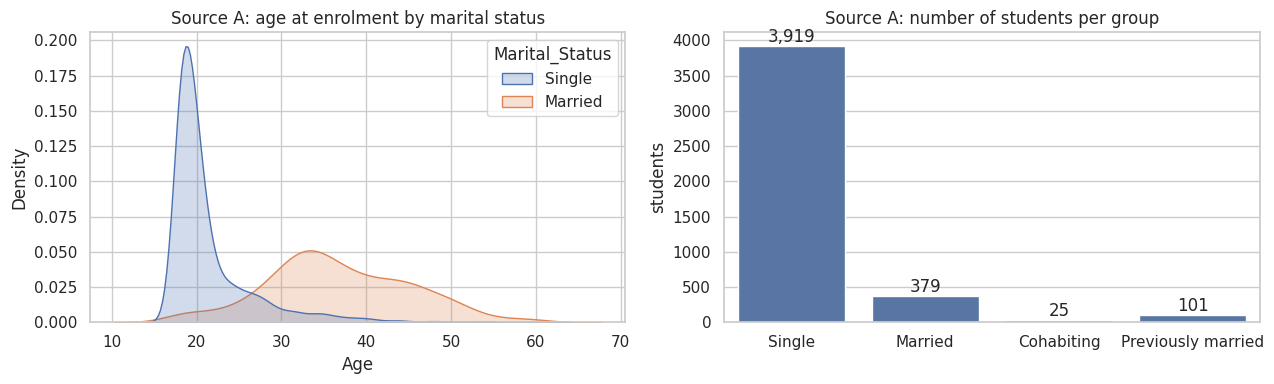

In [12]:
A = clean[clean.Record_Type == "student-level"].copy()
B = clean[clean.Record_Type == "aggregate-count"].copy()
A["Marital_Status"] = A["Marital_Status"].astype(str)

grp_tbl = A.groupby("Marital_Status").agg(
    students=("N", "sum"),
    mean_age=("Age", "mean"), median_age=("Age", "median"),
    mean_grade_20=("Mean_Grade_20", "mean"),
    dropout_rate=("Dropout", "mean"),
    evening_share=("Attendance_Mode", lambda s: (s == "Evening").mean()),
    scholarship_share=("Scholarship", lambda s: (s == "Yes").mean()),
).round(3)
display(grp_tbl)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.kdeplot(data=A[A.Marital_Status.isin(["Single", "Married"])], x="Age", hue="Marital_Status", common_norm=False, fill=True, ax=ax[0])
ax[0].set_title("Source A: age at enrolment by marital status")
order = ["Single", "Married", "Cohabiting", "Previously married"]
cnt = A["Marital_Status"].value_counts().reindex(order)
sns.barplot(x=cnt.index, y=cnt.values, ax=ax[1], color="#4C72B0")
for i, v in enumerate(cnt.values): ax[1].text(i, v, f"{v:,}", ha="center", va="bottom")
ax[1].set_title("Source A: number of students per group"); ax[1].set_ylabel("students"); ax[1].set_xlabel("")
plt.tight_layout(); plt.savefig("figures/01_groups.png", dpi=130); plt.show()

### 6.1 Research questions 1 and 2: performance level distribution, both sources side by side
The two sources are shown in **separate panels**, with the same four-level scale. Percentages are within marital group.

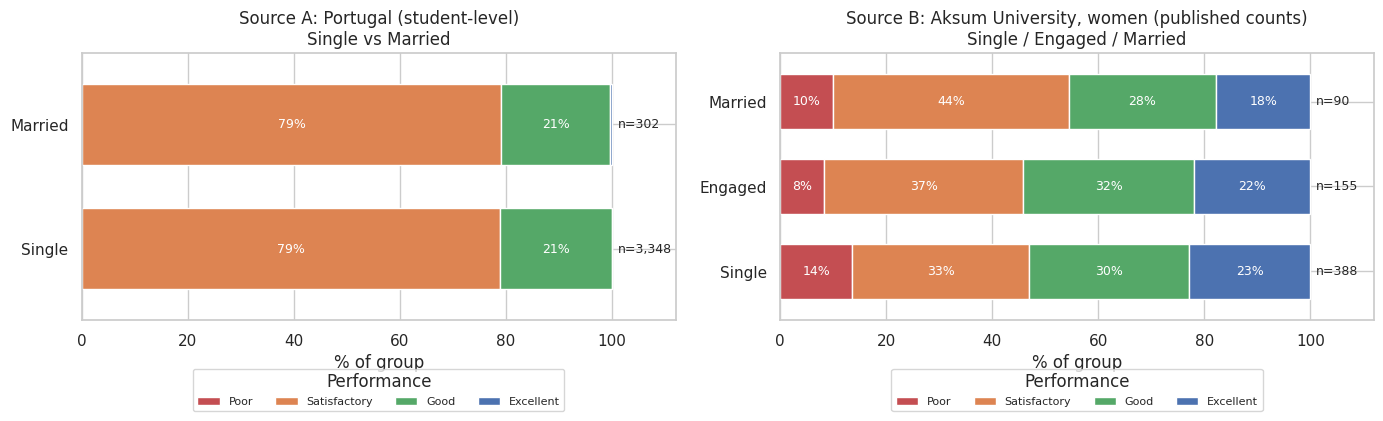

Caveat: Source A grades are compressed (Portuguese 0-20 scale: almost nobody averages below 10 or above 17.5), so the rescaled four-level view is nearly all 'Satisfactory'/'Good'. It is shown for side-by-side context only; the native-grade analysis in 6.2-6.5 is more informative.


Performance_Level,Poor,Satisfactory,Good,Excellent,Total
Marital_Status,,,,,
Single,1,2642,704,1,3348
Married,0,239,62,1,302


Performance_Level,Poor,Satisfactory,Good,Excellent,Total
Marital_Status,,,,,
Single,53,129,117,89,388
Engaged,13,58,50,34,155
Married,9,40,25,16,90


In [13]:
def level_table(frame, group_col):
    t = frame.groupby([group_col, "Performance_Level"], observed=True)["N"].sum().unstack(fill_value=0)
    return t.reindex(columns=level_order, fill_value=0)

def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

A_lv = A[A.Performance_Level.notna() & A.Marital_Status.isin(["Single", "Married"])]
tA = level_table(A_lv, "Marital_Status").loc[["Single", "Married"]]
tB = level_table(B[B.Marital_Status.notna()], "Marital_Status").loc[["Single", "Engaged", "Married"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
palette = ["#C44E52", "#DD8452", "#55A868", "#4C72B0"]
for ax, t, ttl in [(axes[0], tA, "Source A: Portugal (student-level)\nSingle vs Married"),
                   (axes[1], tB, "Source B: Aksum University, women (published counts)\nSingle / Engaged / Married")]:
    pct = t.div(t.sum(axis=1), axis=0) * 100
    pct.plot(kind="barh", stacked=True, color=palette, ax=ax, width=0.65)
    for i, (idx, r) in enumerate(pct.iterrows()):
        x = 0
        for lv in level_order:
            if r[lv] >= 6: ax.text(x + r[lv] / 2, i, f"{r[lv]:.0f}%", ha="center", va="center", color="white", fontsize=9)
            x += r[lv]
        ax.text(101, i, f"n={int(t.loc[idx].sum()):,}", va="center", fontsize=9)
    ax.set_title(ttl); ax.set_xlabel("% of group"); ax.set_ylabel(""); ax.set_xlim(0, 112); ax.legend(title="Performance", loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, fontsize=8)
plt.tight_layout(); plt.savefig("figures/02_levels_by_source.png", dpi=130); plt.show()
print("Caveat: Source A grades are compressed (Portuguese 0-20 scale: almost nobody averages below 10 or above 17.5), so the rescaled four-level view is nearly all 'Satisfactory'/'Good'. It is shown for side-by-side context only; the native-grade analysis in 6.2-6.5 is more informative.")
display(tA.assign(Total=tA.sum(axis=1)))
display(tB.assign(Total=tB.sum(axis=1)))

In [14]:
# Statistical comparison, married vs unmarried, within each source (never pooled across sources).
def compare(tbl, married="Married", others=("Single",), label=""):
    unm = tbl.loc[list(others)].sum()
    mar = tbl.loc[married]
    cont = np.array([mar.values, unm.values])
    chi2, p, dof, _ = stats.chi2_contingency(cont)
    n = cont.sum(); v = np.sqrt(chi2 / (n * (min(cont.shape) - 1)))
    poor_m, poor_u = mar["Poor"], unm["Poor"]
    hi_m, hi_u = mar[["Good", "Excellent"]].sum(), unm[["Good", "Excellent"]].sum()
    out = {
        "comparison": label, "n_married": int(mar.sum()), "n_unmarried": int(unm.sum()),
        "%Poor married": 100 * poor_m / mar.sum(), "%Poor unmarried": 100 * poor_u / unm.sum(),
        "%Good+Excellent married": 100 * hi_m / mar.sum(), "%Good+Excellent unmarried": 100 * hi_u / unm.sum(),
        "chi2": chi2, "dof": dof, "p_value": p, "Cramers_V": v,
    }
    lo, hi = wilson(poor_m, mar.sum()); out["Poor married 95% CI"] = f"{100*lo:.1f}-{100*hi:.1f}"
    lo, hi = wilson(poor_u, unm.sum()); out["Poor unmarried 95% CI"] = f"{100*lo:.1f}-{100*hi:.1f}"
    # ordinal effect: probability a random married student ranks above a random unmarried one (common-language effect size)
    lv = np.arange(4)
    pm, pu = mar.values / mar.sum(), unm.values / unm.sum()
    greater = sum(pm[i] * pu[j] for i in lv for j in lv if i > j); tie = sum(pm[i] * pu[i] for i in lv)
    out["P(married > unmarried) + 0.5*ties"] = greater + 0.5 * tie
    return out

res = pd.DataFrame([
    compare(tA, "Married", ("Single",), "A: UCI Portugal, married vs single"),
    compare(tB, "Married", ("Single", "Engaged"), "B: Aksum, married vs unmarried (single+engaged)"),
    compare(tB, "Married", ("Single",), "B: Aksum, married vs single only"),
]).set_index("comparison").round(3)
display(res.T)

comparison,"A: UCI Portugal, married vs single","B: Aksum, married vs unmarried (single+engaged)","B: Aksum, married vs single only"
n_married,302,90,90
n_unmarried,3348,543,388
%Poor married,0.0,10.0,10.0
%Poor unmarried,0.03,12.155,13.66
%Good+Excellent married,20.861,45.556,45.556
%Good+Excellent unmarried,21.057,53.407,53.093
chi2,4.713,3.519,4.369
dof,3,3,3
p_value,0.194,0.318,0.224
Cramers_V,0.036,0.075,0.096


### 6.2 Source A deep dive: grades, units passed and dropout
Only Source A has real grades, so the detailed comparison is done here. Groups with very few students (cohabiting n=25, previously married n~100) are shown in the plots but not tested.

Mean grade (0-20) - single: 12.72 (n=3348), married: 12.53 (n=302)
Difference (married - single): -0.19 points | Welch t p=0.02 | Mann-Whitney p=0.0021 | Cohen's d=-0.15


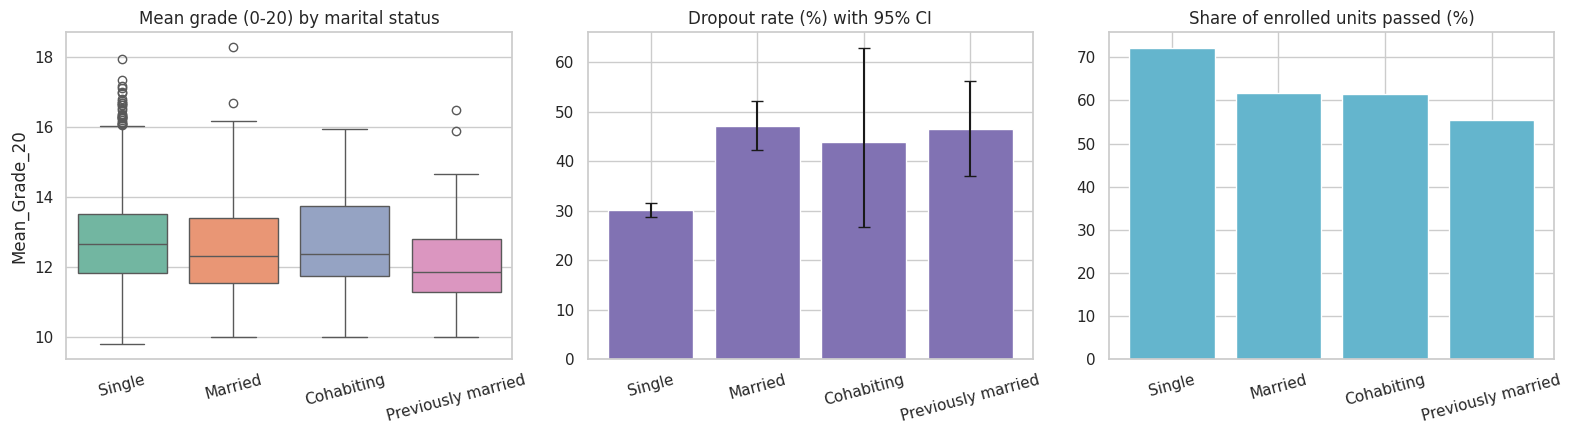

,mean,dropouts,students,dropout_pct
Marital_Status,,,,
Single,0.302118,1184.0,3919,30.2
Married,0.472296,179.0,379,47.2
Cohabiting,0.440000,11.0,25,44.0
Previously married,0.465347,47.0,101,46.5


Outcome_Target,Dropout,Enrolled,Graduate
Marital_Status,,,
Single,0.302,0.184,0.514
Married,0.472,0.137,0.391
Cohabiting,0.440,0.120,0.440
Previously married,0.465,0.188,0.347


In [15]:
S = A[A.Marital_Status.isin(["Single", "Married"]) & A.Mean_Grade_20.notna()].copy()
gs = S[S.Marital_Status == "Single"]["Mean_Grade_20"]; gm = S[S.Marital_Status == "Married"]["Mean_Grade_20"]
u, p_u = stats.mannwhitneyu(gm, gs, alternative="two-sided")
t, p_t = stats.ttest_ind(gm, gs, equal_var=False)
pooled_sd = np.sqrt((gm.var() * (len(gm)-1) + gs.var() * (len(gs)-1)) / (len(gm)+len(gs)-2))
d = (gm.mean() - gs.mean()) / pooled_sd
print(f"Mean grade (0-20) - single: {gs.mean():.2f} (n={len(gs)}), married: {gm.mean():.2f} (n={len(gm)})")
print(f"Difference (married - single): {gm.mean()-gs.mean():.2f} points | Welch t p={p_t:.2g} | Mann-Whitney p={p_u:.2g} | Cohen's d={d:.2f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
order = ["Single", "Married", "Cohabiting", "Previously married"]
sns.boxplot(data=A[A.Mean_Grade_20.notna()], x="Marital_Status", y="Mean_Grade_20", order=order, ax=ax[0], palette="Set2")
ax[0].set_title("Mean grade (0-20) by marital status"); ax[0].set_xlabel(""); ax[0].tick_params(axis="x", rotation=15)
dr = A.groupby("Marital_Status")["Dropout"].agg(["mean", "sum", "count"]).reindex(order)
lo_hi = [wilson(k, n) for k, n in zip(dr["sum"], dr["count"])]
ax[1].bar(order, dr["mean"] * 100, color="#8172B3", yerr=[[100*(m-l) for m,(l,h) in zip(dr["mean"], lo_hi)], [100*(h-m) for m,(l,h) in zip(dr["mean"], lo_hi)]], capsize=4)
ax[1].set_title("Dropout rate (%) with 95% CI"); ax[1].tick_params(axis="x", rotation=15)
ar = A.groupby("Marital_Status")["Approval_Rate"].mean().reindex(order) * 100
ax[2].bar(order, ar.values, color="#64B5CD"); ax[2].set_title("Share of enrolled units passed (%)"); ax[2].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.savefig("figures/03_grades_dropout_units.png", dpi=130); plt.show()
display(dr.assign(dropout_pct=(dr["mean"]*100).round(1)).rename(columns={"sum":"dropouts","count":"students"}))
display(A.groupby("Marital_Status")["Outcome_Target"].value_counts(normalize=True).unstack().reindex(order).round(3))

Note: "Dropout" here means the dataset's `Target` is *Dropout*; students still *Enrolled* and *Graduates* both count as "not dropped out".

### 6.3 Is age driving the gap? (confounding check)
Married students in Source A are about 15 years older at enrolment. That is a different kind of student (often mature students who work). Two checks:
1. **Age-restricted comparison:** compare only students aged 25 or older.
2. **Regression adjustment:** OLS of mean grade on marital status with age, gender, scholarship and attendance mode as controls (robust standard errors).

These reduce, but cannot remove, confounding: work status, income, field of study and prior ability are not available.

In [16]:
older = S[S.Age >= 25]
print("Students aged >= 25:", older.groupby("Marital_Status").size().to_dict())
g1 = older[older.Marital_Status == "Single"]["Mean_Grade_20"]; g2 = older[older.Marital_Status == "Married"]["Mean_Grade_20"]
print(f"Age >= 25  mean grade single {g1.mean():.2f} vs married {g2.mean():.2f} | diff {g2.mean()-g1.mean():.2f} | Mann-Whitney p={stats.mannwhitneyu(g2, g1)[1]:.3g}")
dr_old = A[(A.Age >= 25) & A.Marital_Status.isin(["Single","Married"])].groupby("Marital_Status")["Dropout"].agg(["mean","sum","count"])
print("Dropout among age >= 25:"); display(dr_old.round(3))
ct = np.array([[dr_old.loc["Married","sum"], dr_old.loc["Married","count"]-dr_old.loc["Married","sum"]],
               [dr_old.loc["Single","sum"], dr_old.loc["Single","count"]-dr_old.loc["Single","sum"]]])
print("Chi-square test of dropout, married vs single, age >= 25: p = %.3g" % stats.chi2_contingency(ct)[1])

# OLS with HC1 robust SEs (numpy only)
def ols(y, X, names):
    X = np.column_stack([np.ones(len(X)), X]); beta = np.linalg.lstsq(X, y, rcond=None)[0]
    res = y - X @ beta; n, k = X.shape
    XtXi = np.linalg.inv(X.T @ X)
    meat = X.T @ (X * (res**2)[:, None]); cov = XtXi @ meat @ XtXi * n / (n - k)
    se = np.sqrt(np.diag(cov)); tval = beta / se; pval = 2 * (1 - stats.t.cdf(np.abs(tval), n - k))
    return pd.DataFrame({"coef": beta, "robust_se": se, "p_value": pval}, index=["Intercept"] + names).round(4), 1 - res.var() / y.var()

M = S.copy()
Xdf = pd.DataFrame({
    "Married(vs Single)": (M.Marital_Status == "Married").astype(float),
    "Age": M.Age, "Male(vs Female)": (M.Gender == "Male").astype(float),
    "Scholarship": (M.Scholarship == "Yes").astype(float), "Evening class": (M.Attendance_Mode == "Evening").astype(float)})
m1, r1 = ols(M.Mean_Grade_20.values, Xdf[["Married(vs Single)"]].values, ["Married(vs Single)"])
m2, r2 = ols(M.Mean_Grade_20.values, Xdf.values, list(Xdf.columns))
print("\nModel 1 (unadjusted), R2 = %.3f" % r1); display(m1)
print("Model 2 (adjusted for age, gender, scholarship, evening class), R2 = %.3f" % r2); display(m2)

Students aged >= 25: {'Married': 278, 'Single': 480}
Age >= 25  mean grade single 12.47 vs married 12.50 | diff 0.03 | Mann-Whitney p=0.693
Dropout among age >= 25:


,mean,sum,count
Marital_Status,,,
Married,0.489,173.0,354
Single,0.605,404.0,668


Chi-square test of dropout, married vs single, age >= 25: p = 0.000474

Model 1 (unadjusted), R2 = 0.002


,coef,robust_se,p_value
Intercept,12.7181,0.0217,0.0000
Married(vs Single),-0.1894,0.0807,0.0189


Model 2 (adjusted for age, gender, scholarship, evening class), R2 = 0.035


,coef,robust_se,p_value
Intercept,12.8488,0.0983,0.0000
Married(vs Single),0.1339,0.1068,0.2098
Age,-0.0051,0.0046,0.2646
Male(vs Female),-0.2163,0.0463,0.0000
Scholarship,0.2662,0.0456,0.0000
Evening class,-0.4682,0.0811,0.0000


### 6.4 Attendance pattern (daytime vs evening) and scholarship, Source A
Evening attendance is the only available proxy for time constraints (many evening students work). It is a proxy, not a measure of time management.

,% evening classes,% scholarship holders
Marital_Status,,
Single,6.9,26.4
Married,44.1,9.5
Cohabiting,16.0,20.0
Previously married,41.6,24.8


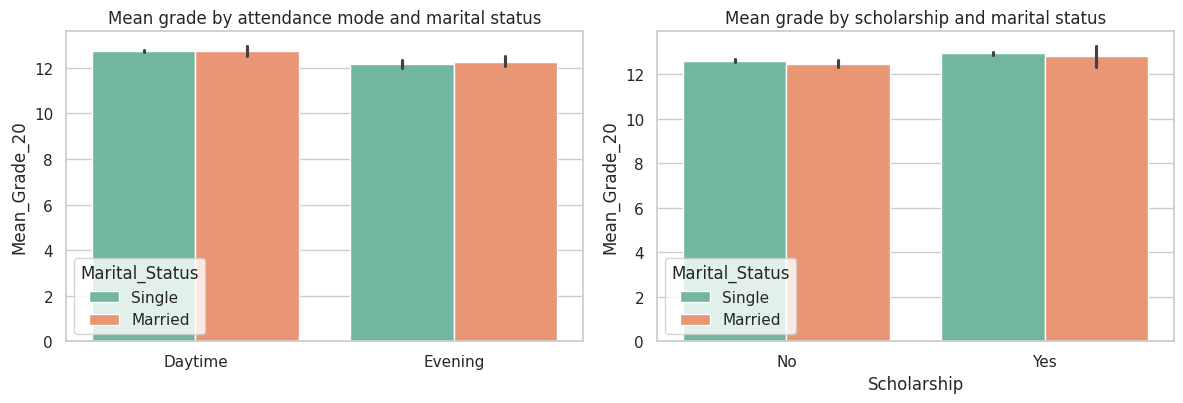

                                 mean  count
Attendance_Mode Marital_Status              
Daytime         Married         12.74    165
                Single          12.76   3128
Evening         Married         12.28    137
                Single          12.19    220


In [17]:
att = A[A.Marital_Status.isin(["Single","Married","Cohabiting","Previously married"])].groupby("Marital_Status")["Attendance_Mode"].value_counts(normalize=True).unstack().reindex(order) * 100
sch = A.groupby("Marital_Status")["Scholarship"].apply(lambda s: (s == "Yes").mean() * 100).reindex(order)
cmp = pd.DataFrame({"% evening classes": att["Evening"], "% scholarship holders": sch}).round(1)
display(cmp)

S2 = A[A.Marital_Status.isin(["Single","Married"]) & A.Mean_Grade_20.notna()]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sns.barplot(data=S2, x="Attendance_Mode", y="Mean_Grade_20", hue="Marital_Status", ax=ax[0], errorbar=("ci", 95), palette="Set2")
ax[0].set_title("Mean grade by attendance mode and marital status"); ax[0].set_xlabel("")
sns.barplot(data=S2, x="Scholarship", y="Mean_Grade_20", hue="Marital_Status", ax=ax[1], errorbar=("ci", 95), palette="Set2")
ax[1].set_title("Mean grade by scholarship and marital status")
plt.tight_layout(); plt.savefig("figures/04_attendance_scholarship.png", dpi=130); plt.show()
print(S2.groupby(["Attendance_Mode","Marital_Status"], observed=True)["Mean_Grade_20"].agg(["mean","count"]).round(2))

### 6.5 Age bands: does the pattern hold at every age?
Comparing married vs single within the same age band is a simple way to see whether the gap is just an age effect.

mean          count       
Marital_Status Married Single Married Single
Age_band                                    
<=20             13.45  12.83      13   2250
21-24            12.26  12.49      11    618
25-29            12.52  12.38      32    268
30-39            12.44  12.65     139    162
40+              12.56  12.36     107     50

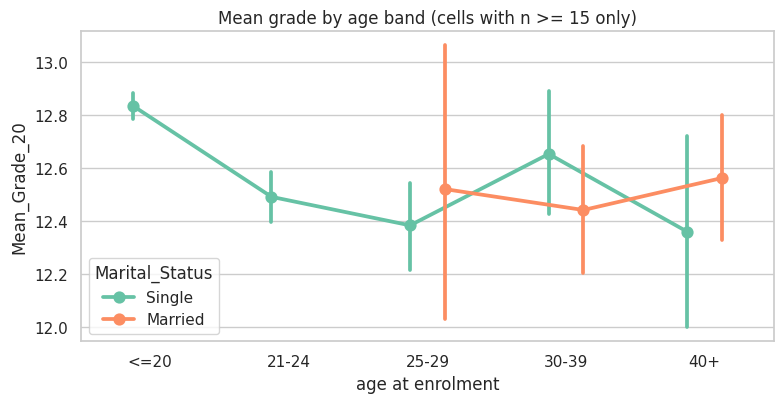

In [18]:
S3 = S.copy()
S3["Age_band"] = pd.cut(S3.Age, [0, 20, 24, 29, 39, 100], labels=["<=20", "21-24", "25-29", "30-39", "40+"])
tab = S3.groupby(["Age_band", "Marital_Status"], observed=True)["Mean_Grade_20"].agg(["mean", "count"]).unstack()
display(tab.round(2))
plot = S3[S3.groupby(["Age_band","Marital_Status"], observed=True)["Mean_Grade_20"].transform("count") >= 15]
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.pointplot(data=plot, x="Age_band", y="Mean_Grade_20", hue="Marital_Status", errorbar=("ci", 95), dodge=0.25, ax=ax, palette="Set2")
ax.set_title("Mean grade by age band (cells with n >= 15 only)"); ax.set_xlabel("age at enrolment")
plt.tight_layout(); plt.savefig("figures/05_age_bands.png", dpi=130); plt.show()

### 6.6 What the data can and cannot say about study habits, motivation and benefits/challenges
I looked for fields on study habits, time management, motivation, benefits and challenges **split by marital status** in both sources:
- **Source A** has none of these (only attendance mode, scholarship and unit counts, used above as weak proxies).
- **Source B** reports study habits, stress and other factors by performance level, but its published tables do **not** cross them with marital status, so married and unmarried students cannot be compared on them without inventing numbers. The notebook does not do that.

So questions about *benefits and challenges* and *motivation* cannot be answered from these two sources. That is a data limit, not a finding that no difference exists.

In [19]:
# Evidence for the statement above: which Source B variables exist at all in Table 1, and is any of them a habit/motivation measure?
print("Variables in Source B Table 1:", table1_df["Variable"].drop_duplicates().tolist())
tmp = soup.find_all("table")
print("Tables in the article:", len(tmp))
print("Does any Source B table row combine marital status with a study-habit/stress/motivation variable?",
      "no (marital status only appears as a row of Table 1)")

Variables in Source B Table 1: ['Childhood Residence', 'Religion', 'Marital Status', 'Age (Mean ± SD)', 'College', 'Year of Study', 'Income per Month', 'Current Place of Living', "Mother's Education", '', "Father's Education"]
Tables in the article: 5
Does any Source B table row combine marital status with a study-habit/stress/motivation variable? no (marital status only appears as a row of Table 1)


## 7. Key findings
*(Numbers below are read from the outputs of the cells above, executed on 24 Nov 2026. Re-running re-fetches the sources and recomputes them.)*

**1. Do married and unmarried students differ in academic outcomes?** Only slightly, and not in a consistent direction.
- *Source A (Portugal, 4,424 students; 379 married vs 3,919 single).* Raw mean grade is a little lower for married students (12.53 vs 12.72 out of 20, difference -0.19, Cohen's d = -0.15, a small effect). Married students are far older (mean age about 36.7 vs 21.5). After adjusting for age, gender, scholarship and evening attendance the married coefficient is +0.13 (p = 0.21, not significant), and among students aged 25+ the mean grades are almost identical (12.50 married vs 12.47 single, p = 0.69). So the raw gap is explained by who the married students are, not shown to be about marriage itself.
- *Source B (Aksum University, women, n = 633; 90 married).* Married students had the highest "Satisfactory" share (44%) and a similar "Poor" share (10% vs 13.7% of single students); Good + Excellent was 45.6% for married vs 53.1% for single. The overall difference is not statistically significant (chi-square p = 0.22 married vs single, p = 0.32 married vs single + engaged; Cramer's V about 0.1).

**2. Which group does better?** Neither clearly. Married students show slightly lower raw grades in Source A and a slightly smaller share of top performers in Source B, but both differences are small, and the Source A gap disappears once age and attendance mode are accounted for. Dropout is the one large difference (see 3).

**3. Dropout, units passed and attendance (Source A only).** 47.2% of married students have the outcome "Dropout" vs 30.2% of single students. This is mostly an age effect too: among students aged 25+ the order reverses (48.9% of married vs 60.5% of single students dropped out, p < 0.001). Married students much more often attend evening classes (44% vs 7%) and less often hold a scholarship (9.5% vs 26.4%). Evening attendance goes with lower grades (about -0.5 points) for both groups. Evening class is the only time-constraint proxy in the data. It is not a measure of time management or motivation.

**4. Benefits, challenges, study habits, motivation.** Cannot be answered from these sources. Source A has no such fields. Source B publishes study habits, stress and other factors by performance level but never cross-tabulated with marital status. The notebook does not guess these.

**5. Pattern across the sources.** Both point the same way on the main question (no strong, clear marriage penalty or advantage in grades; small raw differences), but they use different populations, scales and data types, so they are compared side by side, not pooled into one number.

In [20]:
print("Final unified table:", clean.shape, "| saved to Marriage_Academic_Combined.csv")
print("Records per source:\n", clean.groupby("Source", observed=True)["N"].agg(rows="count", students_represented="sum").to_string())

Final unified table: (4436, 24) | saved to Marriage_Academic_Combined.csv
Records per source:
                                                                              rows  students_represented
Source                                                                                                 
UCI ML Repository #697 (Realinho et al., 2021)                               4424                  4424
Wube, Asgedom & Jemal (2024), Glob Epidemiol 8:100175, PMC11585708, Table 1    12                   633


## 8. Limitations
- **Association, not causation.** Observational data, with no control for work, income, field of study, prior ability or family support. Nothing here shows marriage causes better or worse grades.
- **Different data types.** Source A is student-level; Source B is published aggregate counts (one table, 633 women). They cannot be merged student by student. The unified table stores both with `Record_Type` and `N`.
- **Different populations and grade scales.** Portugal (mixed gender, 0-20 grades) vs Ethiopia (women only, CGPA 0-4). The four-level harmonisation rescales cut-offs and is an assumption. Source A grades are compressed into a narrow range, so that harmonised view carries little information for Source A.
- **Small groups.** Married students are 379 in Source A and 90 in Source B; cohabiting (25) and previously married (101) are too small for firm conclusions. Source A has no "engaged" category, Source B has no "cohabiting" or "previously married".
- **Marital status measured once** (at enrolment in Source A; at survey in Source B), not over time. Whether a student married before or during studies is unknown.
- **"Dropout" is the dataset's outcome label** for the observed period. "Enrolled" students may still drop out later.
- **No benefits/challenges/motivation data** split by marital status (see 6.6).
- Source B published tables only; the study's unreported raw data were not available.

## 9. Conclusion
In these two real datasets, being married during university is **not clearly associated with better or worse grades once the large age difference is taken into account**. Married students are older, more often study in the evening and less often hold scholarships, which is a different set of circumstances from typical single students. Raw dropout is higher for married students, but it reverses among students aged 25+. The data cannot speak to the benefits and challenges students experience, and it cannot support a causal claim. A stronger study would need student-level data with marriage timing, work hours, study habits and motivation measured for both groups.

## 10. References
- Realinho, V., Vieira Martins, M., Machado, J., Baptista, L. (2021). *Predict Students' Dropout and Academic Success* [Dataset]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success
- Wube, T.B., Asgedom, S.G., Jemal, Z.M. (2024). Academic performance and associated factors among female university students. *Global Epidemiology* 8:100175. doi:10.1016/j.gloepi.2024.100175. https://pmc.ncbi.nlm.nih.gov/articles/PMC11585708/